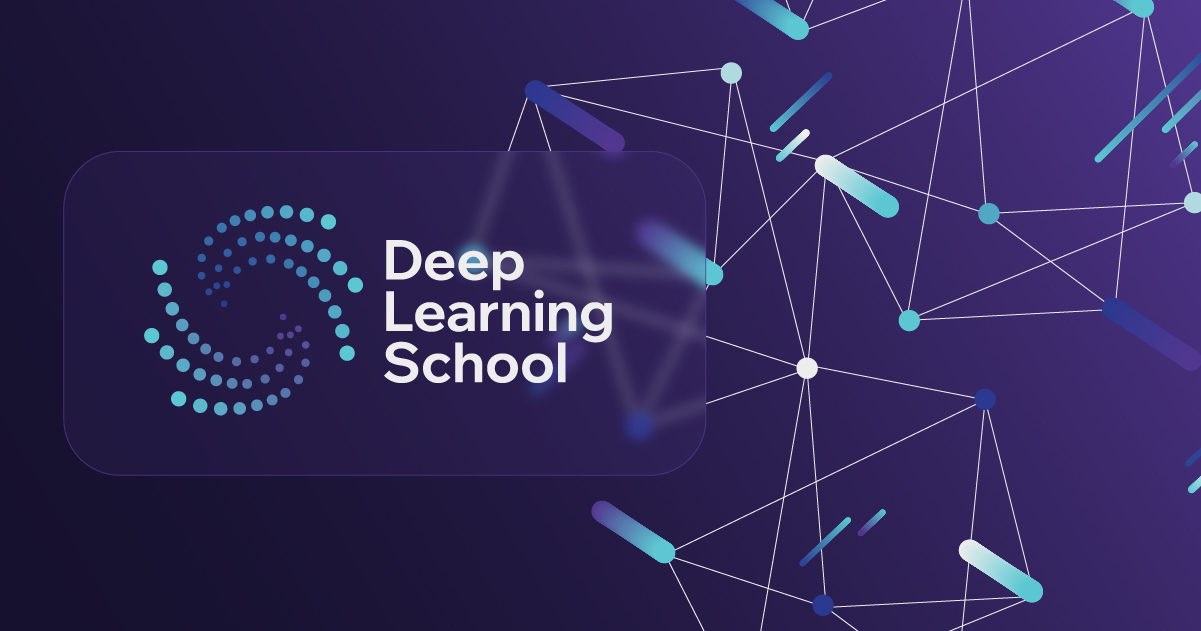

В этом домашнем задании вам предстоит самостоятельно решить задачу классификации текстов на основе семинарского кода. Мы будем использовать датасет [ag_news](https://paperswithcode.com/dataset/ag-news). Это датасет для классификации новостей на 4 темы: "World", "Sports", "Business", "Sci/Tech".

Установим модуль datasets, чтобы нам проще было работать с данными.

<h3 style="text-align: center;"><b>Школа глубокого обучения ФПМИ МФТИ</b></h3>

<h1 style="text-align: center;"><b>Домашнее задание. Нейросетевая классификация текстов </b></h1>

In [42]:
!pip install datasets

The history saving thread hit an unexpected error (OperationalError('attempt to write a readonly database')).History will not be written to the database.


Импорт необходимых библиотек

In [3]:
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
import datasets

import numpy as np
import matplotlib.pyplot as plt

from tqdm.auto import tqdm
from datasets import load_dataset
from nltk.tokenize import word_tokenize
from sklearn.model_selection import train_test_split
import nltk

from collections import Counter
from typing import List
import string

import seaborn
seaborn.set(palette='summer')

In [4]:
nltk.download('punkt_tab')

[nltk_data] Downloading package punkt_tab to /usr/share/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


True

In [5]:
device = 'cuda' if torch.cuda.is_available() else 'cpu'
device

'cuda'

## Подготовка данных
Для вашего удобства, мы привели код обработки датасета в ноутбуке. Ваша задача --- обучить модель, которая получит максимальное возможное качество на тестовой части.

In [6]:
# Загрузим датасет
dataset = datasets.load_dataset('fancyzhx/ag_news')

README.md:   0%|          | 0.00/8.07k [00:00<?, ?B/s]

data/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 18.6MB            

data/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

data/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 1.23MB            

data/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/120000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/7600 [00:00<?, ? examples/s]

Как и в семинаре, выполним следующие шаги:
* Составим словарь
* Создадим класс WordDataset
* Выделим обучающую и тестовую часть, создадим DataLoader-ы.

In [8]:
words = Counter()

for example in tqdm(dataset['train']['text']):
    # Приводим к нижнему регистру и убираем пунктуацию
    prccessed_text = example.lower().translate(
        str.maketrans('', '', string.punctuation))

    for word in word_tokenize(prccessed_text):
        words[word] += 1


vocab = set(['<unk>', '<bos>', '<eos>', '<pad>'])
counter_threshold = 25

for char, cnt in words.items():
    if cnt > counter_threshold:
        vocab.add(char)

print(f'Размер словаря: {len(vocab)}')

word2ind = {char: i for i, char in enumerate(vocab)}
ind2word = {i: char for char, i in word2ind.items()}

  0%|          | 0/120000 [00:00<?, ?it/s]

Размер словаря: 11842


In [9]:
class WordDataset:
    def __init__(self, sentences):
        self.data = sentences
        self.unk_id = word2ind['<unk>']
        self.bos_id = word2ind['<bos>']
        self.eos_id = word2ind['<eos>']
        self.pad_id = word2ind['<pad>']

    def __getitem__(self, idx: int) -> List[int]:
        processed_text = self.data[idx]['text'].lower().translate(
            str.maketrans('', '', string.punctuation))
        tokenized_sentence = [self.bos_id]
        tokenized_sentence += [
            word2ind.get(word, self.unk_id) for word in word_tokenize(processed_text)
            ]
        tokenized_sentence += [self.eos_id]

        train_sample = {
            "text": tokenized_sentence,
            "label": self.data[idx]['label']
        }

        return train_sample

    def __len__(self) -> int:
        return len(self.data)


def collate_fn_with_padding(
    input_batch: List[List[int]], pad_id=word2ind['<pad>'], max_len=256) -> torch.Tensor:
    seq_lens = [len(x['text']) for x in input_batch]
    max_seq_len = min(max(seq_lens), max_len)

    new_batch = []
    for sequence in input_batch:
        sequence['text'] = sequence['text'][:max_seq_len]
        for _ in range(max_seq_len - len(sequence['text'])):
            sequence['text'].append(pad_id)

        new_batch.append(sequence['text'])

    sequences = torch.LongTensor(new_batch).to(device)
    labels = torch.LongTensor([x['label'] for x in input_batch]).to(device)

    new_batch = {
        'input_ids': sequences,
        'label': labels
    }

    return new_batch

In [10]:
train_dataset = WordDataset(dataset['train'])

np.random.seed(42)
idx = np.random.choice(np.arange(len(dataset['test'])), 5000)
eval_dataset = WordDataset(dataset['test'].select(idx))

batch_size = 32
train_dataloader = DataLoader(
    train_dataset, shuffle=True, collate_fn=collate_fn_with_padding, batch_size=batch_size)

eval_dataloader = DataLoader(
    eval_dataset, shuffle=False, collate_fn=collate_fn_with_padding, batch_size=batch_size)

## Постановка задачи
Ваша задача -- получить максимальное возможное accuracy на `eval_dataloader`. Ниже приведена функция, которую вам необходимо запустить для обученной модели, чтобы вычислить качество её работы.

In [11]:
def evaluate(model, eval_dataloader) -> float:
    """
    Calculate accuracy on validation dataloader.
    """

    predictions = []
    target = []
    with torch.no_grad():
        for batch in eval_dataloader:
            logits = model(batch['input_ids'])
            predictions.append(logits.argmax(dim=1))
            target.append(batch['label'])

    predictions = torch.cat(predictions)
    target = torch.cat(target)
    accuracy = (predictions == target).float().mean().item()

    return accuracy

## Ход работы
Оценка за домашнее задание складывается из четырех частей:
### Запуск базовой модели с семинара на новом датасете (1 балл)
На семинаре мы создали модель, которая дает на нашей задаче довольно высокое качество. Ваша цель --- обучить ее и вычислить `score`, который затем можно будет использовать в качестве бейзлайна.

В модели появится одно важное изменение: количество классов теперь равно не 2, а 4. Обратите на это внимание и найдите, что в коде создания модели нужно модифицировать, чтобы учесть это различие.

### Проведение экспериментов по улучшению модели (2 балла за каждый эксперимент)
Чтобы улучшить качество базовой модели, можно попробовать различные идеи экспериментов. Каждый выполненный эксперимент будет оцениваться в 2 балла. Для получения полного балла за этот пункт вам необходимо выполнить по крайней мере 2 эксперимента. Не расстраивайтесь, если какой-то эксперимент не дал вам прироста к качеству: он все равно зачтется, если выполнен корректно.

Вот несколько идей экспериментов:
* **Модель RNN**. Попробуйте другие нейросетевые модели --- LSTM и GRU. Мы советуем обратить внимание на [GRU](https://pytorch.org/docs/stable/generated/torch.nn.GRU.html), так как интерфейс этого класса ничем не отличается от обычной Vanilla RNN, которую мы использовали на семинаре.
* **Увеличение количества рекуррентных слоев модели**. Это можно сделать с помощью параметра `num_layers` в классе `nn.RNN`. В такой модели выходы первой RNN передаются в качестве входов второй RNN и так далее.
* **Изменение архитектуры после применения RNN**. В базовой модели используется агрегация со всех эмбеддингов. Возможно, вы захотите конкатенировать результат агрегации и эмбеддинг с последнего токена.
* **Подбор гиперпараметров и обучение до сходимости**. Возможно, для получения более высокого качества просто необходимо увеличить количество эпох обучения нейросети, а также попробовать различные гиперпараметры: размер словаря, `dropout_rate`, `hidden_dim`.

Обратите внимание, что главное правило проведения экспериментов --- необходимо совершать одно архитектурное изменение в одном эксперименте. Если вы совершите несколько изменений, то будет неясно, какое именно из изменений дало прирост к качеству.

### Получение высокого качества (3 балла)
В конце вашей работы вы должны указать, какая из моделей дала лучший результат, и вывести качество, которое дает лучшая модель, с помощью функции `evaluate`. Ваша модель будет оцениваться по метрике `accuracy` следующим образом:
* $accuracy < 0.9$ --- 0 баллов;
* $0.9 \leqslant accuracy < 0.91$ --- 1 балл;
* $0.91 \leqslant accuracy < 0.915$ --- 2 балла;
* $0.915 \leqslant accuracy$ --- 3 балла.

### Оформление отчета (2 балла)
В конце работы подробно опишите все проведенные эксперименты.
* Укажите, какие из экспериментов принесли улучшение, а какие --- нет.
* Проанализируйте графики сходимости моделей в проведенных экспериментах. Являются ли колебания качества обученных моделей существенными в зависимости от эпохи обучения, или же сходимость стабильная?
* Укажите, какая модель получилась оптимальной.

Желаем удачи!

### Возьмем модель из семинара и добавим гиперпараметры для возможности оценки

In [12]:
class CharLM(nn.Module):
    def __init__(
        self, hidden_dim: int, vocab_size: int, num_classes: int = 4,
        aggregation_type: str = 'max'
        ):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, hidden_dim)
        self.rnn = nn.RNN(hidden_dim, hidden_dim, batch_first=True)
        self.linear = nn.Linear(hidden_dim, hidden_dim)
        self.projection = nn.Linear(hidden_dim, num_classes)

        self.non_lin = nn.Tanh()
        self.dropout = nn.Dropout(p=0.1)

        self.aggregation_type = aggregation_type

    def forward(self, input_batch) -> torch.Tensor:
        embeddings = self.embedding(input_batch)  # [batch_size, seq_len, hidden_dim]
        output, _ = self.rnn(embeddings)  # [batch_size, seq_len, hidden_dim]

        if self.aggregation_type == 'max':
            output = output.max(dim=1)[0] #[batch_size, hidden_dim]
        elif self.aggregation_type == 'mean':
            output = output.mean(dim=1) #[batch_size, hidden_dim]
        else:
            raise ValueError("Invalid aggregation_type")

        output = self.dropout(self.linear(self.non_lin(output)))  # [batch_size, hidden_dim]
        prediction = self.projection(self.non_lin(output))  # [batch_size, num_classes]

        return prediction

In [13]:
def train_model(num_epoch = 5):
    eval_steps = len(train_dataloader) // 2


    losses_type = {}
    acc_type = {}

    for aggregation_type in ['max', 'mean']:
        print(f"Starting training for {aggregation_type}")
        losses = []
        acc = []

        model = CharLM(
            hidden_dim=256, vocab_size=len(vocab), aggregation_type=aggregation_type).to(device)
        criterion = nn.CrossEntropyLoss()
        optimizer = torch.optim.Adam(model.parameters())

        for epoch in range(num_epoch):
            epoch_losses = []
            model.train()
            for i, batch in enumerate(tqdm(train_dataloader, desc=f'Training epoch {epoch}:')):
                optimizer.zero_grad()
                logits = model(batch['input_ids'])
                loss = criterion(logits, batch['label'])
                loss.backward()
                optimizer.step()

                epoch_losses.append(loss.item())
                if i % eval_steps == 0:
                    model.eval()
                    acc.append(evaluate(model, eval_dataloader))
                    model.train()

            losses.append(sum(epoch_losses) / len(epoch_losses))

        losses_type[aggregation_type] = losses
        acc_type[aggregation_type] = acc
    return losses_type, acc_type

In [14]:
losses_type, acc_type =  train_model()

Starting training for max


Training epoch 0::   0%|          | 0/3750 [00:00<?, ?it/s]

Training epoch 1::   0%|          | 0/3750 [00:00<?, ?it/s]

Training epoch 2::   0%|          | 0/3750 [00:00<?, ?it/s]

Training epoch 3::   0%|          | 0/3750 [00:00<?, ?it/s]

...

Training epoch 0::   0%|          | 0/3750 [00:00<?, ?it/s]

Training epoch 1::   0%|          | 0/3750 [00:00<?, ?it/s]

Training epoch 2::   0%|          | 0/3750 [00:00<?, ?it/s]

Training epoch 3::   0%|          | 0/3750 [00:00<?, ?it/s]

Training epoch 4::   0%|          | 0/3750 [00:00<?, ?it/s]

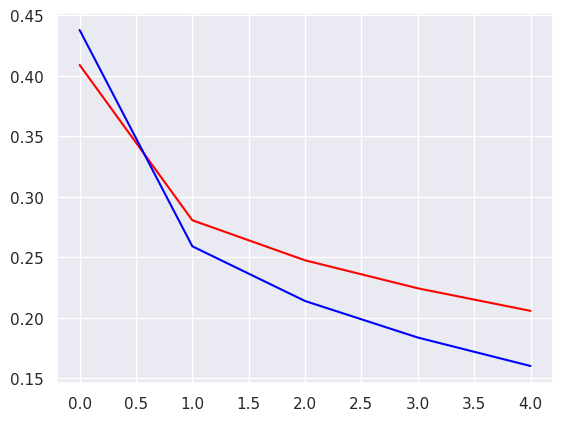

In [16]:
for (name, values), color in zip(losses_type.items(), ['red', 'blue']):
    plt.plot(np.arange(len(losses_type[name])), losses_type[name], color=color, label=name)

Лучшая accuracy для подхода max: 90.06
Лучшая accuracy для подхода mean: 90.86


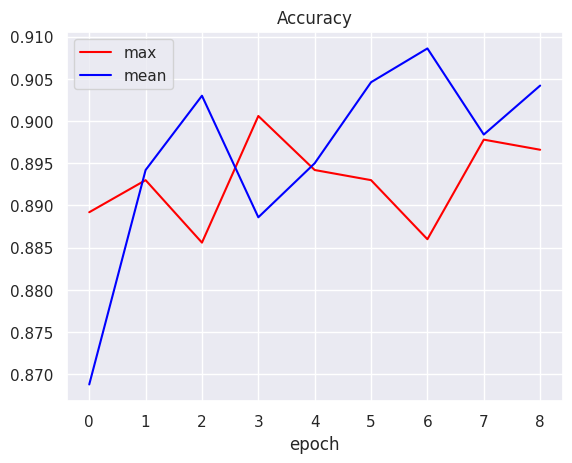

In [17]:
for (name, values), color in zip(losses_type.items(), ['red', 'blue']):
    plt.plot(np.arange(len(acc_type[name][1:])), acc_type[name][1:], color=color, label=name)
    print(f"Лучшая accuracy для подхода {name}: {(max(acc_type[name]) * 100):.2f}")

plt.title('Accuracy')
plt.xlabel("epoch")
plt.legend()
plt.show()

Достаточно неплохие показатели

# Перепишем модель - добавим гиперпараметры для возможности проведения экспериментов

In [18]:
class ExperimentCharLM(nn.Module):
    def __init__(
        self, hidden_dim: int, vocab_size: int, num_classes: int = 4,
        aggregation_type: str = 'max', rnn_layer: str = 'rnn', rnn_layers: int = 1,
        dropout_rate: float = 0.1
        ):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, hidden_dim)
        if rnn_layer == 'rnn':
            self.rnn = nn.RNN(hidden_dim, hidden_dim, batch_first=True, num_layers=rnn_layers)
        elif rnn_layer == 'gru':
            self.rnn = nn.GRU(hidden_dim, hidden_dim, batch_first=True, num_layers=rnn_layers)
        elif rnn_layer == 'lstm':
            self.rnn = nn.LSTM(hidden_dim, hidden_dim, batch_first=True, num_layers=rnn_layers)
        else:
            raise ValueError("Invalid rnn_layer")
        self.linear = nn.Linear(hidden_dim, hidden_dim)
        self.projection = nn.Linear(hidden_dim, num_classes)

        self.non_lin = nn.Tanh()
        self.dropout = nn.Dropout(p=dropout_rate)

        self.aggregation_type = aggregation_type

    def forward(self, input_batch) -> torch.Tensor:
        embeddings = self.embedding(input_batch)  # [batch_size, seq_len, hidden_dim]
        output, _ = self.rnn(embeddings)  # [batch_size, seq_len, hidden_dim]

        if self.aggregation_type == 'max':
            output = output.max(dim=1)[0] #[batch_size, hidden_dim]
        elif self.aggregation_type == 'mean':
            output = output.mean(dim=1) #[batch_size, hidden_dim]
        else:
            raise ValueError("Invalid aggregation_type")

        output = self.dropout(self.linear(self.non_lin(output)))  # [batch_size, hidden_dim]
        prediction = self.projection(self.non_lin(output))  # [batch_size, num_classes]

        return prediction

In [25]:
def train_model(num_epoch = 5, rnn_layer: str = 'rnn', rnn_layers: int = 1,
        dropout_rate: float = 0.1, lr: float = 1e-3):
    eval_steps = len(train_dataloader) // 2


    losses_type = {}
    acc_type = {}

    for aggregation_type in ['max', 'mean']:
        print(f"Starting training for {aggregation_type}")
        losses = []
        acc = []

        model = ExperimentCharLM(
            hidden_dim=256, vocab_size=len(vocab), aggregation_type=aggregation_type, rnn_layer = rnn_layer, rnn_layers = rnn_layers,
        dropout_rate = dropout_rate).to(device)
        criterion = nn.CrossEntropyLoss()
        optimizer = torch.optim.Adam(model.parameters(), lr = lr)

        for epoch in range(num_epoch):
            epoch_losses = []
            model.train()
            for i, batch in enumerate(tqdm(train_dataloader, desc=f'Training epoch {epoch}:')):
                optimizer.zero_grad()
                logits = model(batch['input_ids'])
                loss = criterion(logits, batch['label'])
                loss.backward()
                optimizer.step()

                epoch_losses.append(loss.item())
                if i % eval_steps == 0:
                    model.eval()
                    acc.append(evaluate(model, eval_dataloader))
                    model.train()

            losses.append(sum(epoch_losses) / len(epoch_losses))

        losses_type[aggregation_type] = losses
        acc_type[aggregation_type] = acc
    return losses_type, acc_type

## Попробуем модель с GRU

Starting training for max


Training epoch 0::   0%|          | 0/3750 [00:00<?, ?it/s]

Training epoch 1::   0%|          | 0/3750 [00:00<?, ?it/s]

Training epoch 2::   0%|          | 0/3750 [00:00<?, ?it/s]

Training epoch 3::   0%|          | 0/3750 [00:00<?, ?it/s]

...

Training epoch 1::   0%|          | 0/3750 [00:00<?, ?it/s]

Training epoch 2::   0%|          | 0/3750 [00:00<?, ?it/s]

Training epoch 3::   0%|          | 0/3750 [00:00<?, ?it/s]

Training epoch 4::   0%|          | 0/3750 [00:00<?, ?it/s]

Лучшая accuracy для подхода max: 91.28
Лучшая accuracy для подхода mean: 91.54


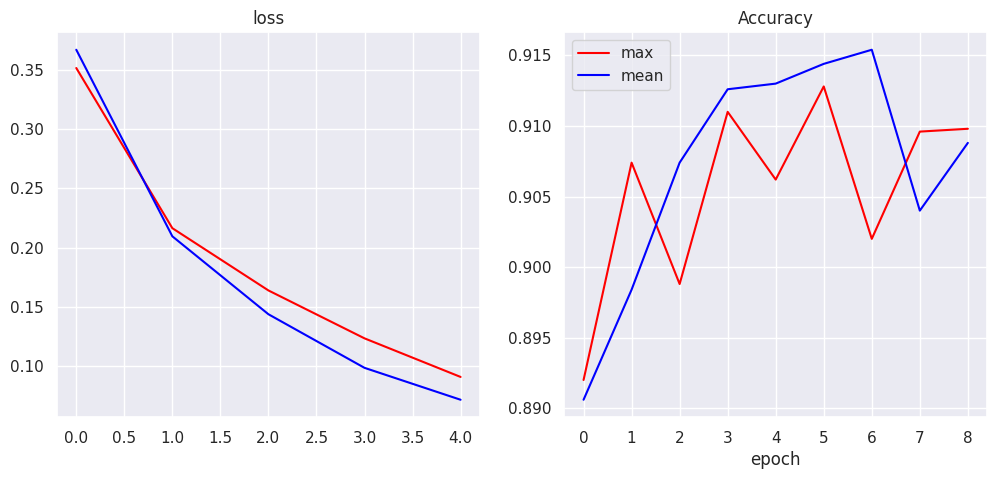

In [20]:
losses_type, acc_type =  train_model(rnn_layer="gru")

fig, axs = plt.subplots(1, 2, figsize=(12, 5))
for (name, values), color in zip(losses_type.items(), ['red', 'blue']):
    axs[0].plot(np.arange(len(losses_type[name])), losses_type[name], color=color, label=name)

axs[0].set_title("loss")
for (name, values), color in zip(losses_type.items(), ['red', 'blue']):
    axs[1].plot(np.arange(len(acc_type[name][1:])), acc_type[name][1:], color=color, label=name)
    print(f"Лучшая accuracy для подхода {name}: {(max(acc_type[name]) * 100):.2f}")

axs[1].set_title('Accuracy')
axs[1].set_xlabel("epoch")
axs[1].legend()
plt.show()

### Качество выросло, новый слой дал положительный эффект.

# Попробуем GRU с двумя слоями

Starting training for max


Training epoch 0::   0%|          | 0/3750 [00:00<?, ?it/s]

Training epoch 1::   0%|          | 0/3750 [00:00<?, ?it/s]

Training epoch 2::   0%|          | 0/3750 [00:00<?, ?it/s]

Training epoch 3::   0%|          | 0/3750 [00:00<?, ?it/s]

...

Training epoch 1::   0%|          | 0/3750 [00:00<?, ?it/s]

Training epoch 2::   0%|          | 0/3750 [00:00<?, ?it/s]

Training epoch 3::   0%|          | 0/3750 [00:00<?, ?it/s]

Training epoch 4::   0%|          | 0/3750 [00:00<?, ?it/s]

Лучшая accuracy для подхода max: 91.46
Лучшая accuracy для подхода mean: 92.06


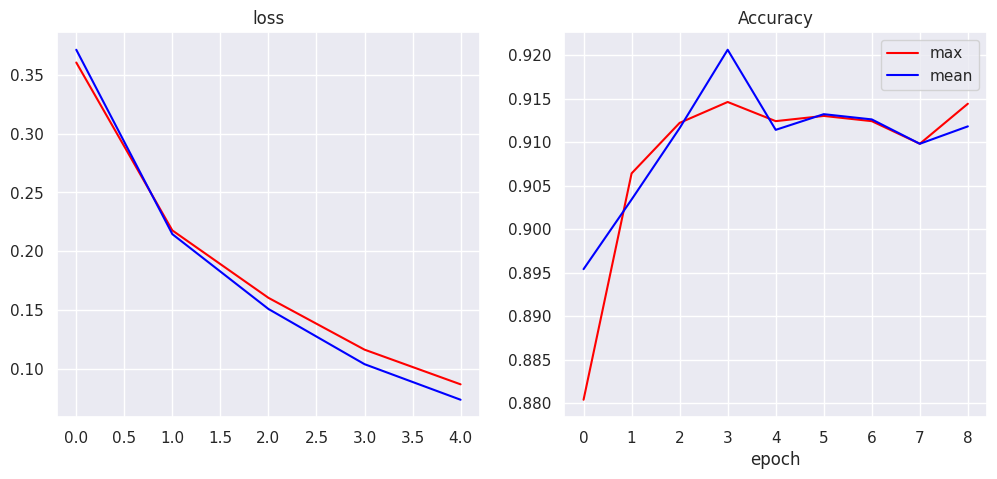

In [23]:
losses_type, acc_type =  train_model(rnn_layer="gru", rnn_layers=2)


fig, axs = plt.subplots(1, 2, figsize=(12, 5))
for (name, values), color in zip(losses_type.items(), ['red', 'blue']):
    axs[0].plot(np.arange(len(losses_type[name])), losses_type[name], color=color, label=name)

axs[0].set_title("loss")
for (name, values), color in zip(losses_type.items(), ['red', 'blue']):
    axs[1].plot(np.arange(len(acc_type[name][1:])), acc_type[name][1:], color=color, label=name)
    print(f"Лучшая accuracy для подхода {name}: {(max(acc_type[name]) * 100):.2f}")

axs[1].set_title('Accuracy')
axs[1].set_xlabel("epoch")
axs[1].legend()
plt.show()

## Модель стала еще немного лучше

## Попробуем тоже самое, но возьмем количество эпох в два раза больше

Starting training for max


Training epoch 0::   0%|          | 0/3750 [00:00<?, ?it/s]

Training epoch 1::   0%|          | 0/3750 [00:00<?, ?it/s]

Training epoch 2::   0%|          | 0/3750 [00:00<?, ?it/s]

Training epoch 3::   0%|          | 0/3750 [00:00<?, ?it/s]

...

Training epoch 6::   0%|          | 0/3750 [00:00<?, ?it/s]

Training epoch 7::   0%|          | 0/3750 [00:00<?, ?it/s]

Training epoch 8::   0%|          | 0/3750 [00:00<?, ?it/s]

Training epoch 9::   0%|          | 0/3750 [00:00<?, ?it/s]

Лучшая accuracy для подхода max: 91.04
Лучшая accuracy для подхода mean: 91.44


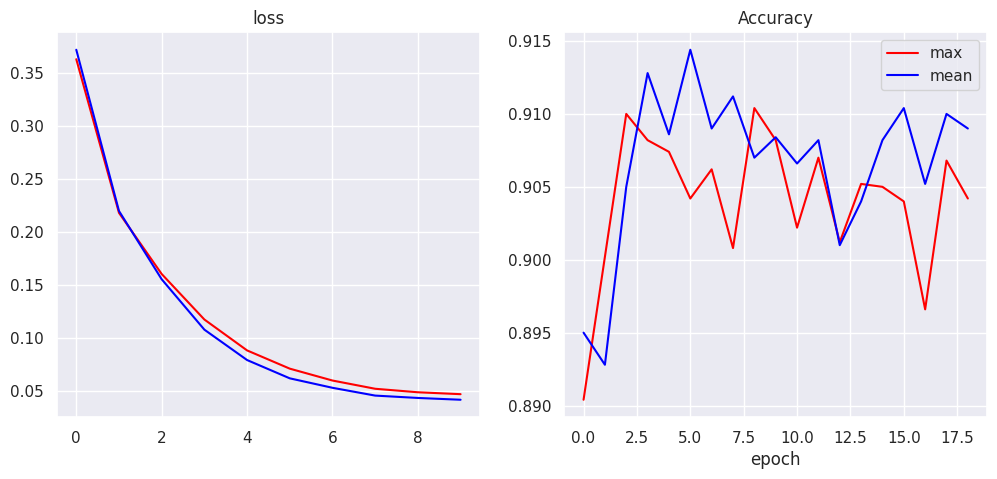

In [24]:
losses_type, acc_type =  train_model(rnn_layer="gru", rnn_layers=2, num_epoch = 10)


fig, axs = plt.subplots(1, 2, figsize=(12, 5))
for (name, values), color in zip(losses_type.items(), ['red', 'blue']):
    axs[0].plot(np.arange(len(losses_type[name])), losses_type[name], color=color, label=name)

axs[0].set_title("loss")
for (name, values), color in zip(losses_type.items(), ['red', 'blue']):
    axs[1].plot(np.arange(len(acc_type[name][1:])), acc_type[name][1:], color=color, label=name)
    print(f"Лучшая accuracy для подхода {name}: {(max(acc_type[name]) * 100):.2f}")

axs[1].set_title('Accuracy')
axs[1].set_xlabel("epoch")
axs[1].legend()
plt.show()

## Большее количество эпох не дали значимого результата, accuracy сильно скачет. Попробуем снизить коэфициент обучения

Starting training for max


Training epoch 0::   0%|          | 0/3750 [00:00<?, ?it/s]

Training epoch 1::   0%|          | 0/3750 [00:00<?, ?it/s]

Training epoch 2::   0%|          | 0/3750 [00:00<?, ?it/s]

Training epoch 3::   0%|          | 0/3750 [00:00<?, ?it/s]

...

Training epoch 6::   0%|          | 0/3750 [00:00<?, ?it/s]

Training epoch 7::   0%|          | 0/3750 [00:00<?, ?it/s]

Training epoch 8::   0%|          | 0/3750 [00:00<?, ?it/s]

Training epoch 9::   0%|          | 0/3750 [00:00<?, ?it/s]

Лучшая accuracy для подхода max: 90.48
Лучшая accuracy для подхода mean: 90.20


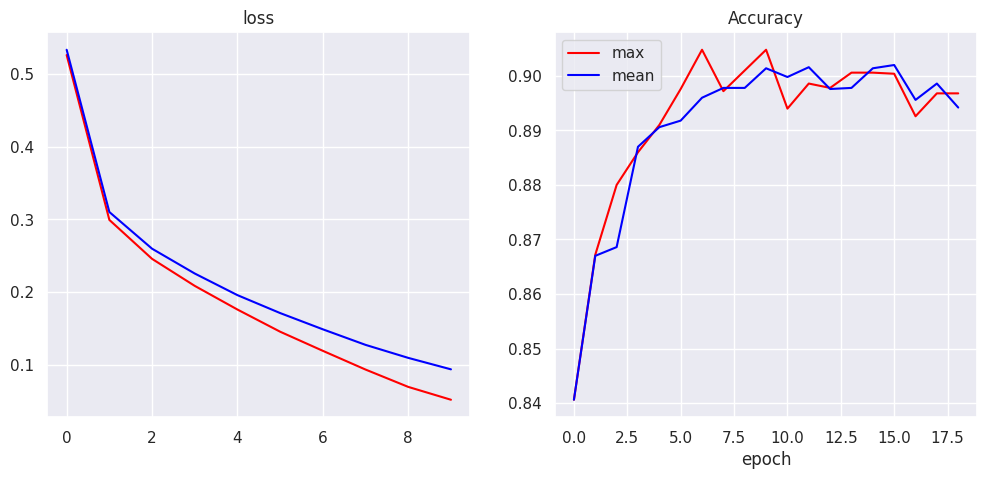

In [26]:
losses_type, acc_type =  train_model(rnn_layer="gru", rnn_layers=2, num_epoch = 10, lr = 1e-4)


fig, axs = plt.subplots(1, 2, figsize=(12, 5))
for (name, values), color in zip(losses_type.items(), ['red', 'blue']):
    axs[0].plot(np.arange(len(losses_type[name])), losses_type[name], color=color, label=name)

axs[0].set_title("loss")
for (name, values), color in zip(losses_type.items(), ['red', 'blue']):
    axs[1].plot(np.arange(len(acc_type[name][1:])), acc_type[name][1:], color=color, label=name)
    print(f"Лучшая accuracy для подхода {name}: {(max(acc_type[name]) * 100):.2f}")

axs[1].set_title('Accuracy')
axs[1].set_xlabel("epoch")
axs[1].legend()
plt.show()

Рост точности стал более стабильным, но сама точность оставляет желать лучшего

## Попробуем переписать модель, будем брать последний выход RNN

In [32]:
class ExperimentCharLM(nn.Module):
    def __init__(
        self, hidden_dim: int, vocab_size: int, num_classes: int = 4,
        rnn_layer: str = 'rnn', rnn_layers: int = 1,
        dropout_rate: float = 0.1, aggregation_type: str = 'max'
        ):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, hidden_dim)
        if rnn_layer == 'rnn':
            self.rnn = nn.RNN(hidden_dim, hidden_dim, batch_first=True, num_layers=rnn_layers)
        elif rnn_layer == 'gru':
            self.rnn = nn.GRU(hidden_dim, hidden_dim, batch_first=True, num_layers=rnn_layers)
        elif rnn_layer == 'lstm':
            self.rnn = nn.LSTM(hidden_dim, hidden_dim, batch_first=True, num_layers=rnn_layers)
        else:
            raise ValueError("Invalid rnn_layer")
        self.linear = nn.Linear(hidden_dim, hidden_dim)
        self.projection = nn.Linear(hidden_dim, num_classes)

        self.non_lin = nn.Tanh()
        self.dropout = nn.Dropout(p=dropout_rate)

        self.aggregation_type = aggregation_type

    def forward(self, input_batch) -> torch.Tensor:
        embeddings = self.embedding(input_batch)  # [batch_size, seq_len, hidden_dim]
        output, _ = self.rnn(embeddings)  # [batch_size, seq_len, hidden_dim]

        if self.aggregation_type == 'max':
            output = output.max(dim=1)[0] #[batch_size, hidden_dim]
        elif self.aggregation_type == 'mean':
            output = output.mean(dim=1) #[batch_size, hidden_dim]
        elif self.aggregation_type == 'last':
            output = output[:, -1, :] #[batch_size, hidden_dim]
        else:
            raise ValueError("Invalid aggregation_type")
        

        output = self.dropout(self.non_lin(self.linear((output))))  # [batch_size, hidden_dim]
        prediction = self.projection(output)  # [batch_size, num_classes]

        return prediction

In [44]:
def train_model(num_epoch = 5, rnn_layer: str = 'rnn', rnn_layers: int = 1,
        dropout_rate: float = 0.1, lr: float = 1e-3, aggregation_types = ['max', 'mean'], hidden_dim = 256):
    eval_steps = len(train_dataloader) // 2


    losses_type = {}
    acc_type = {}

    for aggregation_type in aggregation_types:
        print(f"Starting training for {aggregation_type}")
        losses = []
        acc = []

        model = ExperimentCharLM(
            hidden_dim=hidden_dim, vocab_size=len(vocab), aggregation_type=aggregation_type, rnn_layer = rnn_layer, rnn_layers = rnn_layers,
        dropout_rate = dropout_rate).to(device)
        criterion = nn.CrossEntropyLoss()
        optimizer = torch.optim.Adam(model.parameters(), lr = lr)

        for epoch in range(num_epoch):
            epoch_losses = []
            model.train()
            for i, batch in enumerate(tqdm(train_dataloader, desc=f'Training epoch {epoch}:')):
                optimizer.zero_grad()
                logits = model(batch['input_ids'])
                loss = criterion(logits, batch['label'])
                loss.backward()
                optimizer.step()

                epoch_losses.append(loss.item())
                if i % eval_steps == 0:
                    model.eval()
                    acc.append(evaluate(model, eval_dataloader))
                    model.train()

            losses.append(sum(epoch_losses) / len(epoch_losses))

        losses_type[aggregation_type] = losses
        acc_type[aggregation_type] = acc
    return losses_type, acc_type

In [35]:
losses_type, acc_type =  train_model(rnn_layer="gru", rnn_layers=2, num_epoch = 5, dropout_rate = 0.2, ['max', 'mean', 'last'])

Starting training for max


Training epoch 0::   0%|          | 0/3750 [00:00<?, ?it/s]

Training epoch 1::   0%|          | 0/3750 [00:00<?, ?it/s]

Training epoch 2::   0%|          | 0/3750 [00:00<?, ?it/s]

Training epoch 3::   0%|          | 0/3750 [00:00<?, ?it/s]

...

Training epoch 0::   0%|          | 0/3750 [00:00<?, ?it/s]

Training epoch 1::   0%|          | 0/3750 [00:00<?, ?it/s]

Training epoch 2::   0%|          | 0/3750 [00:00<?, ?it/s]

Training epoch 3::   0%|          | 0/3750 [00:00<?, ?it/s]

Training epoch 4::   0%|          | 0/3750 [00:00<?, ?it/s]

Лучшая accuracy для подхода max: 91.64
Лучшая accuracy для подхода mean: 91.30
Лучшая accuracy для подхода last: 90.94


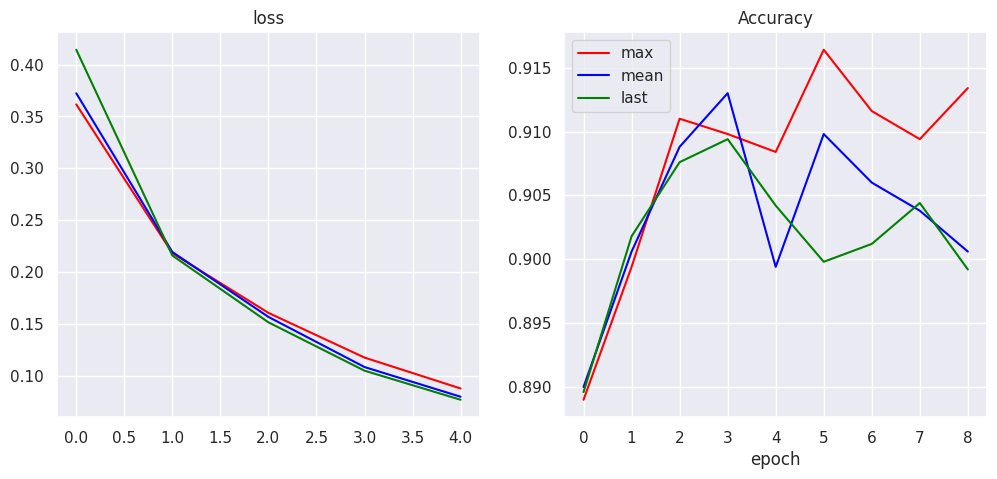

In [36]:
fig, axs = plt.subplots(1, 2, figsize=(12, 5))
for (name, values), color in zip(losses_type.items(), ['red', 'blue', 'green']):
    axs[0].plot(np.arange(len(losses_type[name])), losses_type[name], color=color, label=name)

axs[0].set_title("loss")
for (name, values), color in zip(losses_type.items(), ['red', 'blue', 'green']):
    axs[1].plot(np.arange(len(acc_type[name][1:])), acc_type[name][1:], color=color, label=name)
    print(f"Лучшая accuracy для подхода {name}: {(max(acc_type[name]) * 100):.2f}")

axs[1].set_title('Accuracy')
axs[1].set_xlabel("epoch")
axs[1].legend()
plt.show()

## Last показал себя хуже остальных, вероятно это связано с тем, что мы заполняли маленькие предложения путыми токенами и модель теряет на них смысл. 

Возьмем LSTM

Starting training for max


Training epoch 0::   0%|          | 0/3750 [00:00<?, ?it/s]

Training epoch 1::   0%|          | 0/3750 [00:00<?, ?it/s]

Training epoch 2::   0%|          | 0/3750 [00:00<?, ?it/s]

Training epoch 3::   0%|          | 0/3750 [00:00<?, ?it/s]

...

Training epoch 1::   0%|          | 0/3750 [00:00<?, ?it/s]

Training epoch 2::   0%|          | 0/3750 [00:00<?, ?it/s]

Training epoch 3::   0%|          | 0/3750 [00:00<?, ?it/s]

Training epoch 4::   0%|          | 0/3750 [00:00<?, ?it/s]

Лучшая accuracy для подхода max: 91.42
Лучшая accuracy для подхода mean: 91.72


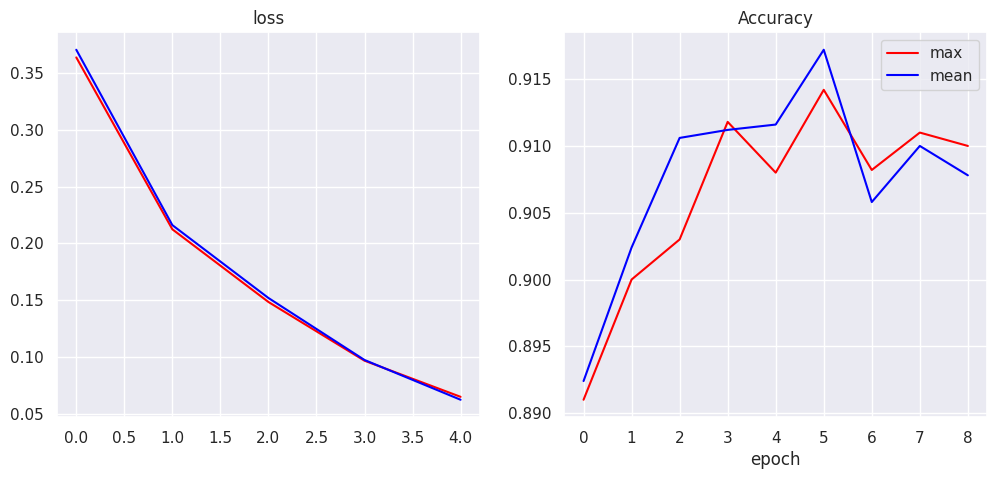

In [40]:
losses_type, acc_type =  train_model(rnn_layer="lstm", rnn_layers=2, num_epoch = 5, dropout_rate = 0.2, aggregation_types = ['max', 'mean'])

fig, axs = plt.subplots(1, 2, figsize=(12, 5))
for (name, values), color in zip(losses_type.items(), ['red', 'blue']):
    axs[0].plot(np.arange(len(losses_type[name])), losses_type[name], color=color, label=name)

axs[0].set_title("loss")
for (name, values), color in zip(losses_type.items(), ['red', 'blue']):
    axs[1].plot(np.arange(len(acc_type[name][1:])), acc_type[name][1:], color=color, label=name)
    print(f"Лучшая accuracy для подхода {name}: {(max(acc_type[name]) * 100):.2f}")

axs[1].set_title('Accuracy')
axs[1].set_xlabel("epoch")
axs[1].legend()
plt.show()

## Попробуем увеличить количество эпох и уменьшить lr

Starting training for max


Training epoch 0::   0%|          | 0/3750 [00:00<?, ?it/s]

Training epoch 1::   0%|          | 0/3750 [00:00<?, ?it/s]

Training epoch 2::   0%|          | 0/3750 [00:00<?, ?it/s]

Training epoch 3::   0%|          | 0/3750 [00:00<?, ?it/s]

...

Training epoch 11::   0%|          | 0/3750 [00:00<?, ?it/s]

Training epoch 12::   0%|          | 0/3750 [00:00<?, ?it/s]

Training epoch 13::   0%|          | 0/3750 [00:00<?, ?it/s]

Training epoch 14::   0%|          | 0/3750 [00:00<?, ?it/s]

Лучшая accuracy для подхода max: 90.76
Лучшая accuracy для подхода mean: 90.78


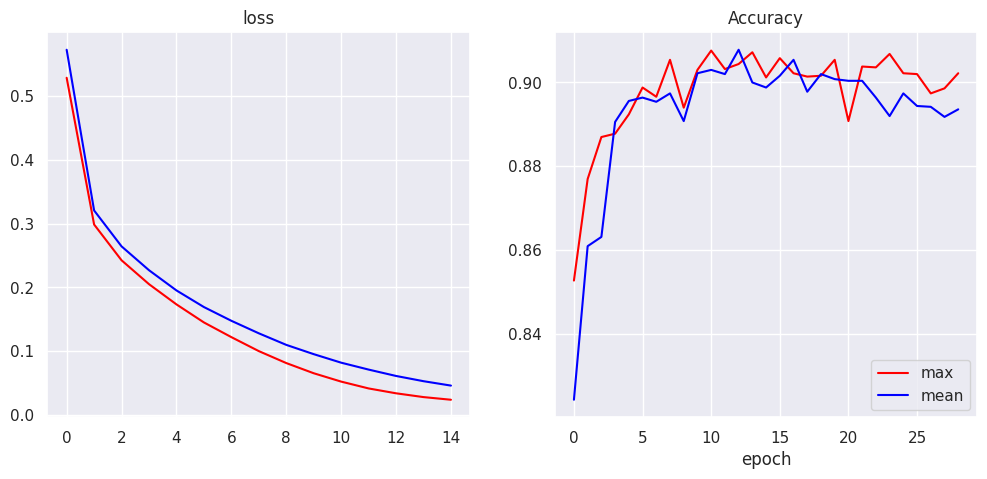

In [41]:
losses_type, acc_type =  train_model(rnn_layer="lstm", rnn_layers=2, num_epoch = 15, lr = 1e-4, dropout_rate = 0.15, aggregation_types = ['max', 'mean'])

fig, axs = plt.subplots(1, 2, figsize=(12, 5))
for (name, values), color in zip(losses_type.items(), ['red', 'blue']):
    axs[0].plot(np.arange(len(losses_type[name])), losses_type[name], color=color, label=name)

axs[0].set_title("loss")
for (name, values), color in zip(losses_type.items(), ['red', 'blue']):
    axs[1].plot(np.arange(len(acc_type[name][1:])), acc_type[name][1:], color=color, label=name)
    print(f"Лучшая accuracy для подхода {name}: {(max(acc_type[name]) * 100):.2f}")

axs[1].set_title('Accuracy')
axs[1].set_xlabel("epoch")
axs[1].legend()
plt.show()

## Можно сделать вывод, что модель обучается эффективно на первых нескольких эпохах, дальше лишь идет переобучение на тренировочных данных, видимо изначальный lr достаточно оптимальный, мы даже можем снизить количество эпох до 3. Нам нужно менять размер модели или ее архитектуру, а не способ ее обучения.


Попробуем взять размер скрытого слоя меньше в 2 раза, возможно получится скомпенсировать переобучение

Starting training for max


Training epoch 0::   0%|          | 0/3750 [00:00<?, ?it/s]

Training epoch 1::   0%|          | 0/3750 [00:00<?, ?it/s]

Training epoch 2::   0%|          | 0/3750 [00:00<?, ?it/s]

Training epoch 3::   0%|          | 0/3750 [00:00<?, ?it/s]

...

Training epoch 1::   0%|          | 0/3750 [00:00<?, ?it/s]

Training epoch 2::   0%|          | 0/3750 [00:00<?, ?it/s]

Training epoch 3::   0%|          | 0/3750 [00:00<?, ?it/s]

Training epoch 4::   0%|          | 0/3750 [00:00<?, ?it/s]

Лучшая accuracy для подхода max: 91.18
Лучшая accuracy для подхода mean: 91.20


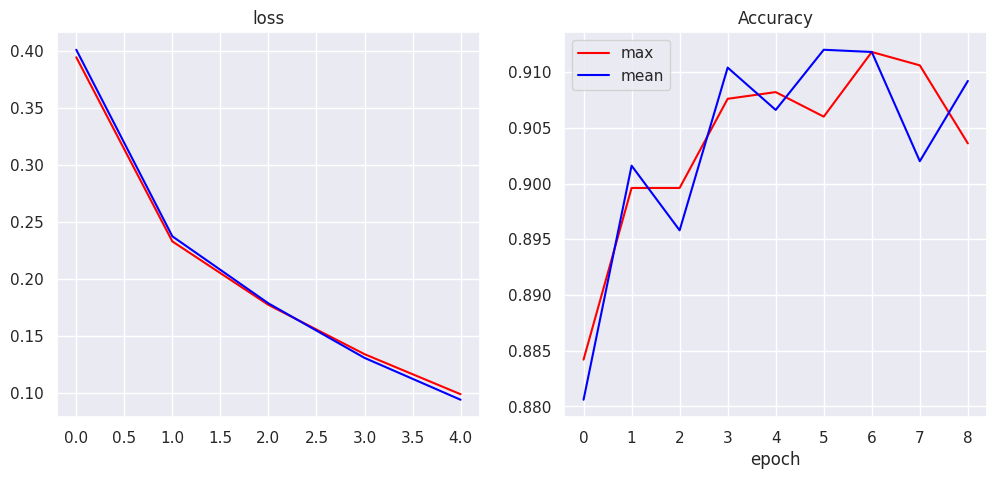

In [57]:
losses_type, acc_type =  train_model(rnn_layer="gru", rnn_layers=2, num_epoch = 5, lr = 1e-3, dropout_rate = 0.1, aggregation_types = ['max', 'mean'], hidden_dim = 128)

fig, axs = plt.subplots(1, 2, figsize=(12, 5))
for (name, values), color in zip(losses_type.items(), ['red', 'blue']):
    axs[0].plot(np.arange(len(losses_type[name])), losses_type[name], color=color, label=name)

axs[0].set_title("loss")
for (name, values), color in zip(losses_type.items(), ['red', 'blue']):
    axs[1].plot(np.arange(len(acc_type[name][1:])), acc_type[name][1:], color=color, label=name)
    print(f"Лучшая accuracy для подхода {name}: {(max(acc_type[name]) * 100):.2f}")

axs[1].set_title('Accuracy')
axs[1].set_xlabel("epoch")
axs[1].legend()
plt.show()

И ради эксперимента попробуем проверить на размере скрытого слоя в два раза больше

Starting training for max


Training epoch 0::   0%|          | 0/3750 [00:00<?, ?it/s]

Training epoch 1::   0%|          | 0/3750 [00:00<?, ?it/s]

Training epoch 2::   0%|          | 0/3750 [00:00<?, ?it/s]

Training epoch 3::   0%|          | 0/3750 [00:00<?, ?it/s]

...

Training epoch 0::   0%|          | 0/3750 [00:00<?, ?it/s]

Training epoch 1::   0%|          | 0/3750 [00:00<?, ?it/s]

Training epoch 2::   0%|          | 0/3750 [00:00<?, ?it/s]

Training epoch 3::   0%|          | 0/3750 [00:00<?, ?it/s]

Лучшая accuracy для подхода max: 91.42
Лучшая accuracy для подхода mean: 91.72


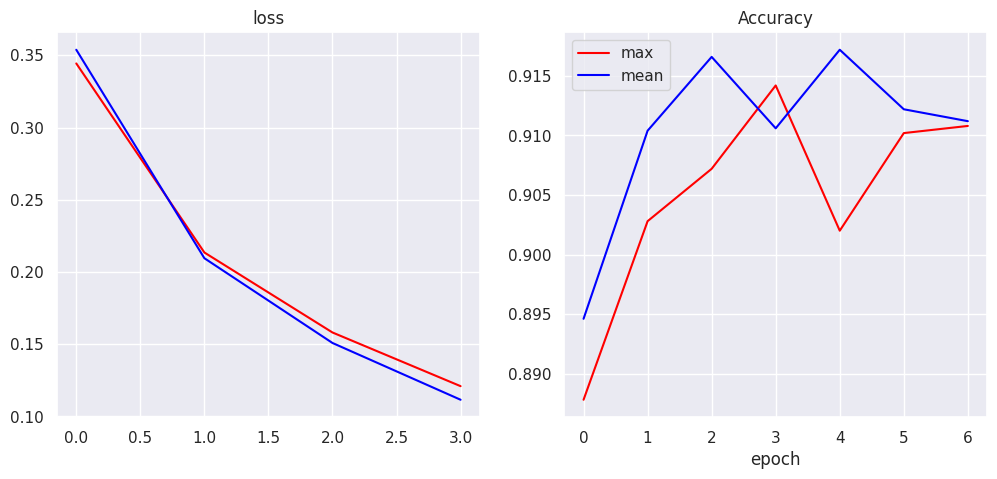

In [59]:
losses_type, acc_type =  train_model(rnn_layer="gru", rnn_layers=2, num_epoch = 4, lr = 1e-3, dropout_rate = 0.1, aggregation_types = ['max', 'mean'], hidden_dim = 512)

fig, axs = plt.subplots(1, 2, figsize=(12, 5))
for (name, values), color in zip(losses_type.items(), ['red', 'blue']):
    axs[0].plot(np.arange(len(losses_type[name])), losses_type[name], color=color, label=name)

axs[0].set_title("loss")
for (name, values), color in zip(losses_type.items(), ['red', 'blue']):
    axs[1].plot(np.arange(len(acc_type[name][1:])), acc_type[name][1:], color=color, label=name)
    print(f"Лучшая accuracy для подхода {name}: {(max(acc_type[name]) * 100):.2f}")

axs[1].set_title('Accuracy')
axs[1].set_xlabel("epoch")
axs[1].legend()
plt.show()

## Как итог: Все модели дают плюс-минус одинаковую точность, но те в которых есть слои GRU или LSTM показывают параметры немного лучше. Изменение шага обучения и количества эпох дали скорее негативный эффект, модель после первых 2-4 эпох начинает переобучаться и точность сильно скачет. Изменеие размера сскрытого слоя дало скорее негативный эффект, при меньшем размере модель хуже понимает данные, при большом - немного лучше. Взятие последнего вектора из RNN дало негативный эффект - из-за того что мы заполняли предложения спец символами до фиксированного размера. 

### Наилучшую точность показала GRU c двумя рекурсивными слоями - на пике точность было равной 92.06 